# Temporal change in gridded data

Now that we have established good ways of extracting quantiative information from regions of interest, we should think about how we might begin to properly trace behaviour through time.

We will begin by thinking about how we might store our stack of data as an `xarray` datacube with a time axis: after this, we will move towards the idea of extracting and plotting time-series data.

In [ ]:
import geopandas as gpd 
import pandas as pd
import rioxarray as rxr
import xarray as xr

import matplotlib.pyplot as plt

from pathlib import Path

import matplotlib.dates as mdates


##  Getting data as a single datacube

Let's load our previous data. First, the fire extend geodataframe:

In [3]:
fire_gdf = gpd.read_file("effis_modis_powys_20260427.gpkg")
fire_gdf = fire_gdf.to_crs(32630)

Now, we will once again extract all relevant filenames within our `powys_data` directory. However, this time, we will also extract the dates from the filenames. We can do this by index slicing, as the filenames have a consistent pattern:

In [10]:
directory = Path("powys_data")

# Get all the  *.tif files in the directory as a list
filepaths = list(directory.glob('*.tif'))

# Ensure files are sorted alphpabetically
filepaths = sorted(filepaths)

print(filepaths)

# Extract dates in the format YYYY-MM-DD from the filenames and store them in a list
dates = []

for f in list(filepaths):

    # Convert from PosixPath to string
    f = str(f)

    # Extract the date string: it runs from the -36th to -26th the index of the filename
    date = f[-36:-26]
    dates.append(date)

print(dates)

[PosixPath('powys_data/powys_2026-04-22_LC92030242026112LGN00.tif'), PosixPath('powys_data/powys_2026-04-29_LC92040242026119LGN00.tif'), PosixPath('powys_data/powys_2026-04-30_LC82030242026120LGN00.tif'), PosixPath('powys_data/powys_2026-05-24_LC92030242026144LGN00.tif')]
['2026-04-22', '2026-04-29', '2026-04-30', '2026-05-24']


Now, we can loop through all the filepaths, appending them to a list. The command `xarray.concat()` will concatenate these together into a single dataset, with a new dimension called `time`. By default, this dimension will just be `(0, 1, 2, 3, ...)`, but we can attatch our `dates` list (which are currently strings of the format `YYYY-MM-DD`) and convert them to datetime objects.

In [11]:
scenes_list = []

for f in filepaths:

    # Open the raster file using rioxarray
    scene = rxr.open_rasterio(f).squeeze()
    scene['band'] = list(scene.attrs["long_name"])

    scenes_list.append(scene)

# xarray.concat() can be used to combine the list of xarray.DataArray objects into a single xarray.DataArray along a new dimension called "time"
scenes = xr.concat(scenes_list, dim="time")

# Make the 'time' dimension match the list of dates extracted from the filenames
scenes['time'] = dates

# convert the time dimension from a YYYY-MM-DD string to a datetime object
scenes['time'] = scenes['time'].values.astype('datetime64[D]')
    

This now gives us a real datacube, with axes `x`, `y`, `band`, and `time`.

In [12]:
scenes

<xarray.DataArray (time: 4, band: 6, y: 570, x: 500)> Size: 27MB
array([[[[0.0181575 , 0.01840501, 0.0229425 , ..., 0.0442275 ,
          0.04378749, 0.04356749],
         [0.020165  , 0.02112749, 0.0229975 , ..., 0.044475  ,
          0.0451625 , 0.04290751],
         [0.02209   , 0.0221725 , 0.0287175 , ..., 0.04274251,
          0.0399375 , 0.0421375 ],
         ...,
         [0.03111   , 0.03204499, 0.02720501, ..., 0.07285501,
          0.06240501, 0.0505525 ],
         [0.0329525 , 0.030725  , 0.0317425 , ..., 0.07359751,
          0.07169999, 0.05462249],
         [0.03600501, 0.03443749, 0.0372425 , ..., 0.06958251,
          0.06930749, 0.05643751]],

        [[0.03660999, 0.03817751, 0.04068001, ..., 0.0806375 ,
          0.08256249, 0.0815175 ],
         [0.0396625 , 0.0411475 , 0.04166999, ..., 0.08272751,
          0.08492748, 0.08077501],
         [0.04345749, 0.0442275 , 0.05343999, ..., 0.08036251,
          0.07799749, 0.077805  ],
...
          0.2637875 , 0.25295252],
         [0.194405  , 0.201555  , 0.1955875 , ..., 0.28672248,
          0.29263502, 0.2503125 ],
         [0.1828825 , 0.20447   , 0.2018025 , ..., 0.28672248,
          0.28947252, 0.26928753]],

        [[       nan,        nan,        nan, ..., 0.10283001,
          0.10074   , 0.09826501],
         [       nan,        nan,        nan, ..., 0.0994475 ,
          0.10071249, 0.09892501],
         [       nan,        nan,        nan, ..., 0.10101499,
          0.09680749, 0.10041   ],
         ...,
         [0.0907575 , 0.10230751, 0.0838825 , ..., 0.16805999,
          0.1533475 , 0.14273249],
         [0.09438749, 0.09969501, 0.09425001, ..., 0.158655  ,
          0.1629725 , 0.1417975 ],
         [0.09950249, 0.10731249, 0.10822   , ..., 0.155795  ,
          0.1560425 , 0.14749001]]]],
      shape=(4, 6, 570, 500), dtype=float32)
Coordinates:
  * time         (time) datetime64[s] 32B 2026-04-22 2026-04-29 ... 2026-05-24
  * band         (band) <U6 144B 'blue' 'green' 'red' 'nir08' 'swir16' 'swir22'
  * y            (y) float64 5kB 5.804e+06 5.804e+06 ... 5.787e+06 5.787e+06
  * x            (x) float64 4kB 4.452e+05 4.453e+05 ... 4.602e+05 4.602e+05
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0
    long_name:      ('blue', 'green', 'red', 'nir08', 'swir16', 'swir22')

## Manipulating the datacube

We can extract individual scenes using `.sel()` (e.g. `scenes.sel(time='2026-04-29')`) or `.isel()`, which we do below to plot all our four scenes as a loop:

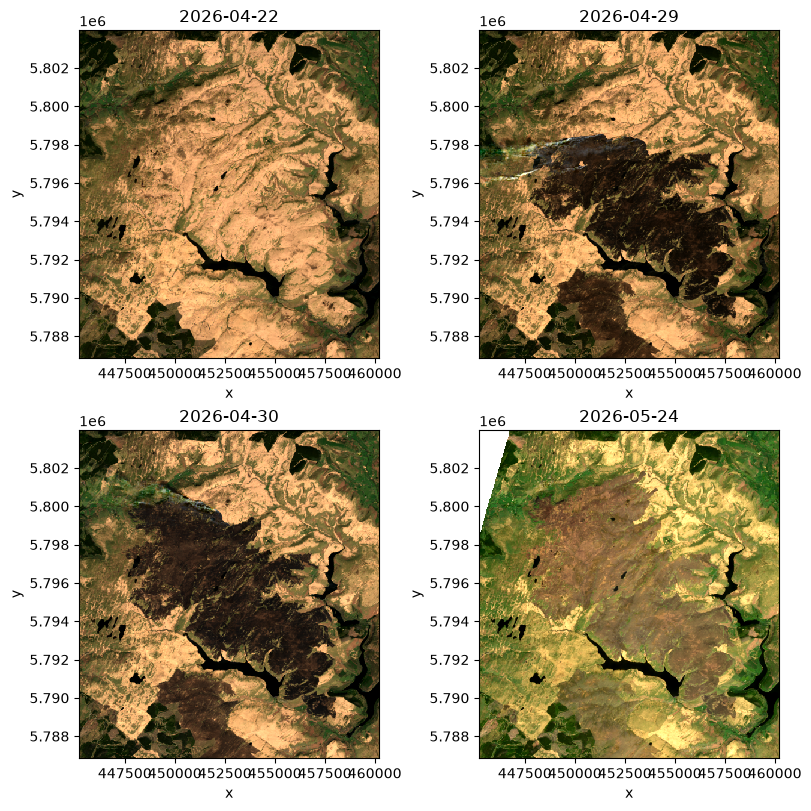

In [ ]:
# plot a 4x4 grid of the scenes using xarray.plot.imshow() with a shared colorbar and a title for each subplot
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(8, 8), layout='constrained')

# Loop through the axes and plot each scene
for i, ax in enumerate(axes.flat):

    # Get the RGB bands for the time index i (range from 0 - 3)
    rgb_i = scenes.sel(band=["red", "green", "blue"]).isel(time=i).squeeze()

    rgb_i.plot.imshow(ax=ax, robust=True)
    
    # Set title to be the date of the scene
    ax.set_title(str(scenes['time'].values[i])[:10])

We can calculate NBI for the whole time stack simply by performing an operation on `scenes`:

In [17]:
# calculate the Normalized Burn Ratio (NBR) for each scene
nbr = (scenes.sel(band="nir08") - scenes.sel(band="swir22")) / (scenes.sel(band="nir08") + scenes.sel(band="swir22"))

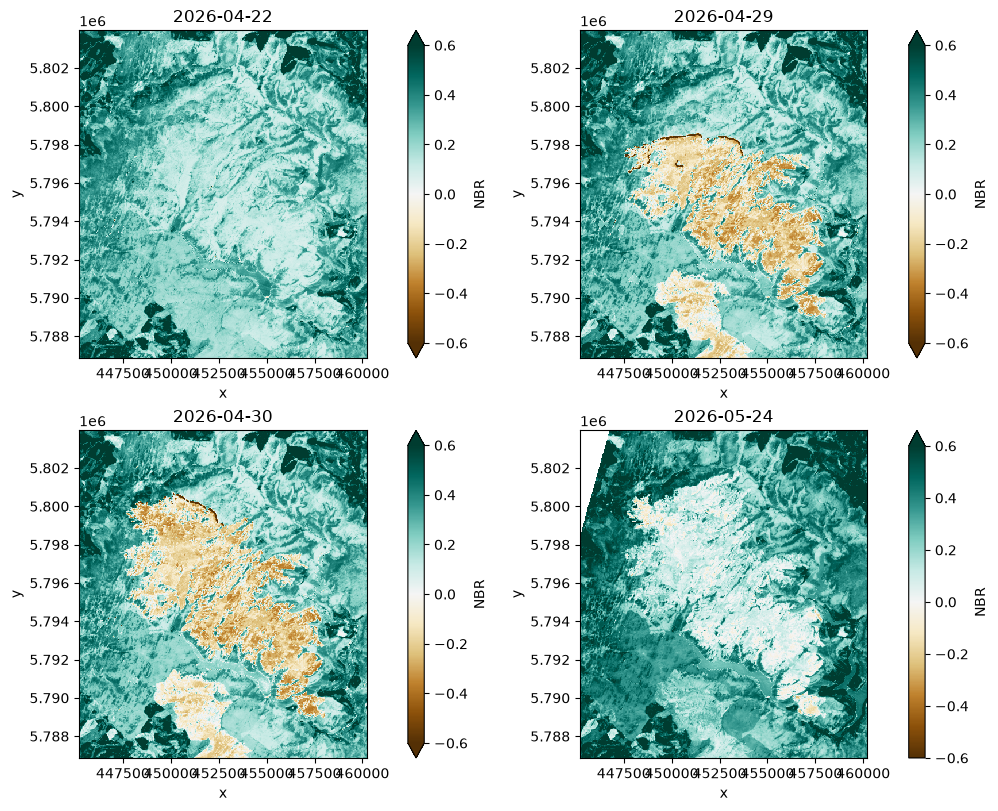

In [18]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 8), layout='constrained')

for i, ax in enumerate(axes.flat):

    nbr_i = nbr.isel(time=i)
    
    nbr_i.plot.imshow(
        ax=ax, cmap="BrBG", 
        vmin=-.6, vmax=.6,
        cbar_kwargs={"label": "NBR"}
        )
    
    # Set title to be the date of the scene
    ax.set_title(str(scenes['time'].values[i])[:10])

    ax.set_aspect('equal')

## Raster differencing

We might choose to plot the _change_ in difference index through time, rather than just getting measurements at individual times. This is particularly valuable amongst users of NBR - in fact, there is even a specific term for it, known as dNBR: the difference in NBR values from before and after the fire. The equation for this (if it even needs a formal equation) is be unsurprising:

$$dNBR = NBR_{prefire} - NBR_{postfire} $$

We can calculate it by comparing the full stack to our pre-fire image (`band` index `0`).

In [20]:
dnbr = nbr.isel(time=0) - nbr

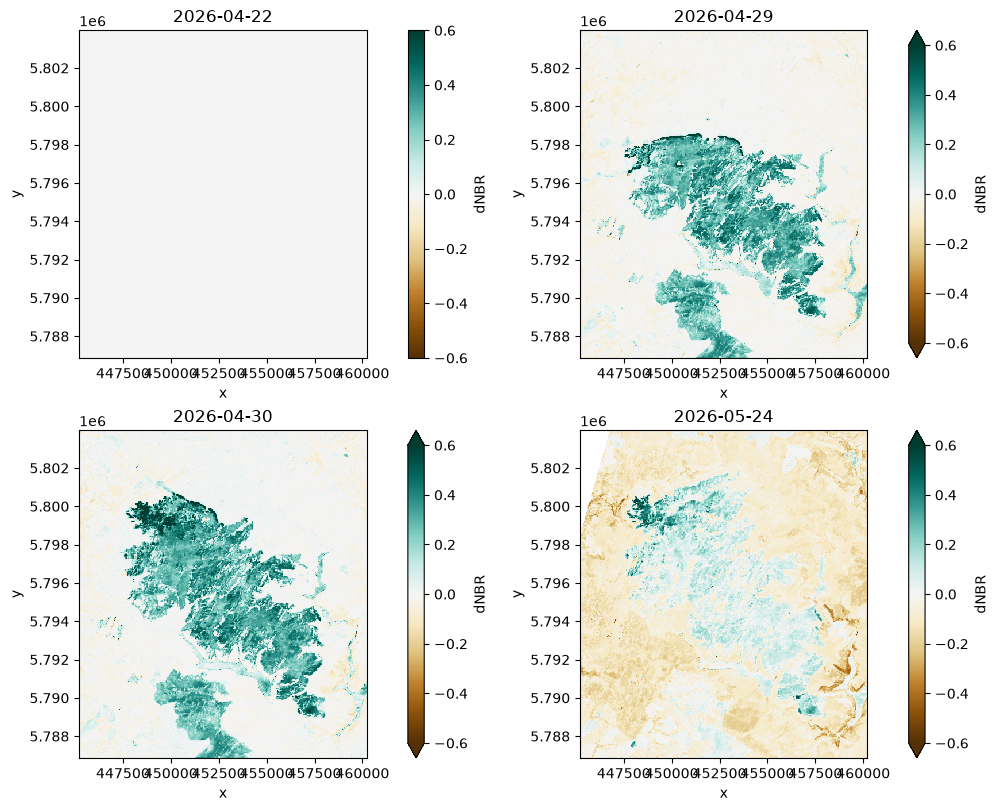

In [21]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 8), layout='constrained')

for i, ax in enumerate(axes.flat):

    dnbr_i = dnbr.isel(time=i)
    
    dnbr_i.plot.imshow(
        ax=ax, cmap="BrBG", 
        vmin=-.6, vmax=.6,
        cbar_kwargs={"label": "dNBR"}
        )
    
    # Set title to be the date of the scene
    ax.set_title(str(scenes['time'].values[i])[:10])

    ax.set_aspect('equal')

## Calculating change in area through time

dNBR is commonly thresholded to identify regions of burned regions. The UN-SPIDER (United Nations Platform for Space-based Information for Disaster Management and Emergency Response) [web page on Normalised Burn Ratio](https://un-spider.org/advisory-support/recommended-practices/recommended-practice-burn-severity/in-detail/normalized-burn-ratio) contains the following recommended thresholds for interpreting dNBR:

```{figure} ../../img/un-spider-nbr.png
:alt: Burn severity levels for given dNBR values
:class: bh-primary
:width: 850px
:align: center
Burn severity levels for given dNBR values. (credit: [UN-SPIDER](https://un-spider.org/advisory-support/recommended-practices/recommended-practice-burn-severity/in-detail/normalized-burn-ratio))
```
Let's calculate the area subjected to at least moderate-low severity (i.e. dNBR valus >0.27), also performing a sensitivity analysis of ±0.01.

In fact, we can probably wrap this up into a generic function that will work for various opportunities:


In [22]:
def calculate_thresholded_area(xds, threshold, pixel_area, threshold_type='greater'):
    """
    Calculate the area of pixels in an xarray.DataArray that exceed a given threshold.

    Parameters:
    - xds: xarray.DataArray with dimensions (time, y, x)
    - threshold: float, the threshold value to compare against
    - threshold_type: str, either 'greater' or 'less', indicating whether to count pixels greater than or less than the threshold
    - pixel_area: float, the area of each pixel

    Returns:
    - float, the total area of pixels exceeding the threshold
    """
    
    # Create a boolean mask based on the threshold type
    if threshold_type == 'greater':
        mask = xds > threshold
    elif threshold_type == 'less':
        mask = xds < threshold
    else:
        raise ValueError("threshold_type must be either 'greater' or 'less'")
    
    # Count the number of True values (pixels exceeding the threshold) for each time step
    area_counts = mask.sum().item()
    area = area_counts * pixel_area  # Convert count to area in square meters

    return area


In [30]:
dnbr_threshold = 0.270  # Threshold for burn severity
sensitivity = 0.01

pixel_area = 30 * 30 / 1e6  # Pixel are in km: each pixel is 30m x 30m

dates = dnbr['time'].values
list_area_burned = []
list_area_burned_upper = []
list_area_burned_lower = []

for i, time in enumerate(dnbr['time'].values):

    dnbr_i = dnbr.isel(time=i)

    area_burned = calculate_thresholded_area(dnbr_i, dnbr_threshold, pixel_area, threshold_type='greater')
    area_burned_upper = calculate_thresholded_area(dnbr_i, dnbr_threshold - sensitivity, pixel_area, threshold_type='greater')
    area_burned_lower = calculate_thresholded_area(dnbr_i, dnbr_threshold + sensitivity, pixel_area, threshold_type='greater')

    list_area_burned.append(area_burned)
    list_area_burned_lower.append(area_burned_lower)
    list_area_burned_upper.append(area_burned_upper)

df_area_burned = pd.DataFrame({
    'date': dates,
    'area_burned': list_area_burned,
    'area_burned_lower': list_area_burned_lower,
    'area_burned_upper': list_area_burned_upper
})

df_area_burned

,date,area_burned,area_burned_lower,area_burned_upper
0,2026-04-22,0.0000,0.0000,0.0000
1,2026-04-29,33.0714,30.7917,35.2269
2,2026-04-30,41.9625,39.3849,44.4690
3,2026-05-24,2.9016,2.6955,3.1176


/Users/ju24811/miniforge3/envs/geospatial/lib/python3.12/site-packages/pandas/plotting/_matplotlib/core.py:1382: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.errorbar(data[x].values, data[y].values, linestyle="none", **err_kwds)


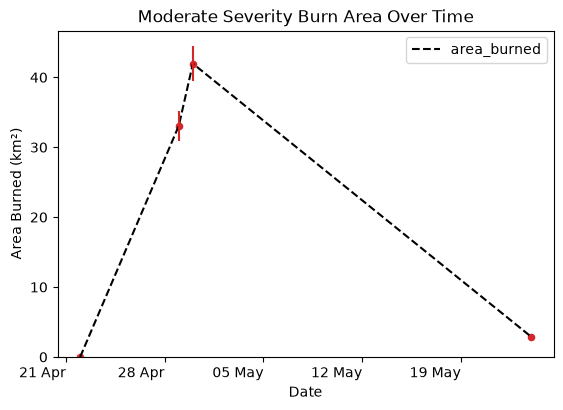

In [ ]:
# Error bars require the lower and upper error values to be calculated 
# as the difference between the mean and the lower/upper bounds
y_upper_err = df_area_burned['area_burned'] - df_area_burned['area_burned_lower']
y_lower_err = df_area_burned['area_burned_upper'] - df_area_burned['area_burned']
yerr = [y_lower_err, y_upper_err]

# Begin plotting
fig, ax = plt.subplots()

# Plot dashed connector line
df_area_burned.plot(x='date', y='area_burned', ax=ax, color='k', ls='--')

# Plot point data with error bars
df_area_burned.plot.scatter(x='date', y='area_burned', yerr=yerr, ax=ax, color='tab:red')

ax.set_ylim(0, None)
ax.set_xlabel('Date')
ax.set_ylabel('Area Burned (km²)')

ax.set_title('Moderate Severity Burn Area Over Time')

# A couple additional lines of codes to make the x-axis ticks more 
# readable, labelled like "28 Apr"
ax.xaxis.set_major_locator(mdates.WeekdayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))

plt.show()

As we can see qualitatively in the original RGB imagery, there was a continuation of the fire in the north of the region between 2026-04-29 and 2026-04-30 that led to an increase in total burned area.

It's remarkable how quickly the NBR recovers following the burn!

## Calculating change in zonal statistics through time

An alternative approach might be to calculate a change in some zonal statistic through time. 

Let's calculate the mean and standard deviation dNBR values through time. Using the `xarray` interface, this is remarkably simple!

In [36]:
dnbr_clipped = dnbr.rio.clip(fire_gdf.geometry, fire_gdf.crs, drop=True)

# Calculate the mean values of the clipped dNBR for each time step
mean_dnbr_clipped = dnbr_clipped.mean(dim=['x', 'y'])

# Calculate the standard deviation of the clipped dNBR for each time step
std_dnbr_clipped = dnbr_clipped.std(dim=['x', 'y'])

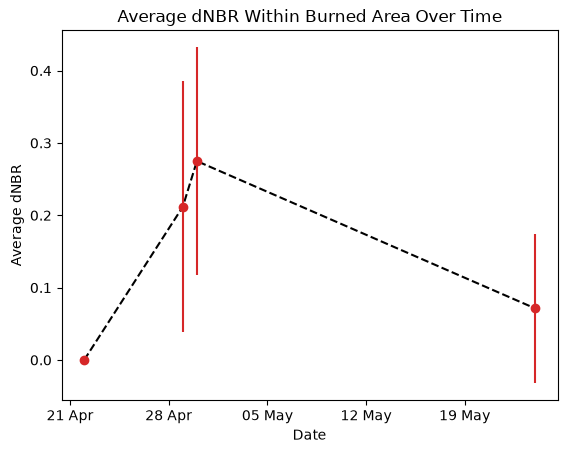

In [59]:
fig, ax = plt.subplots()

mean_dnbr_clipped.plot(ax=ax, color='k', ls='--')

# Have to fall back to using ax.errorbar as the xarray plot.scatter 
# can't accept the yerr argument for some reason...
ax.errorbar(mean_dnbr_clipped['time'], mean_dnbr_clipped, yerr=std_dnbr_clipped, fmt='o', color='tab:red')

ax.set_xlabel('Date')
ax.set_ylabel('Average dNBR')

ax.set_title('Average dNBR Within Burned Area Over Time')

# A couple additional lines of codes to make the x-axis ticks more 
# readable, labelled like "28 Apr"
ax.xaxis.set_major_locator(mdates.WeekdayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))

plt.show()

A similar pattern, but our measure of variance is much higher: the NBR pixels are much noisier, and on some dates our region is only partially burned. 

For our purposes here, it is likely that presenting the area, rather than the mean dNBR is probably the correct choice.

## Staistical summaries through the time dimension

Once you have a few scenes within a single stack, there may be reasons why you might want to calculate a statistical measure through time. 

For example, calculating the `median` of the stack might be useful for getting you monthly/seasonal average values - this is particularly useful when you are trying to get a good image of a cloudy region, as calculating the median can help eliminate cloudy pixels.

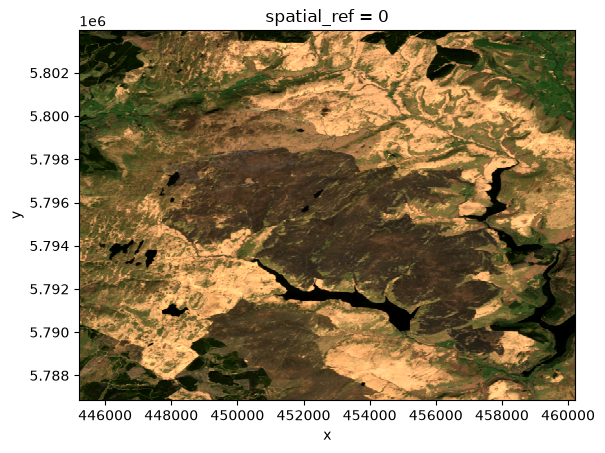

In [65]:
rgb_median = scenes.sel(band=["red", "green", "blue"]).median(dim="time")

rgb_median.plot.imshow(robust=True)
plt.show()

Alternatively, rather than trying to find the average of many scenes, sometimes it might be more useful to try and assess how scenes _differ_ - for instance, by calculating the standard deviation of a time stack. By calculating the standard deviaiton of our NDI measurements, we can see where things have varied the most through our images, which clearly highlights the burned area:

In [62]:
nbr_std = nbr.std(dim="time")

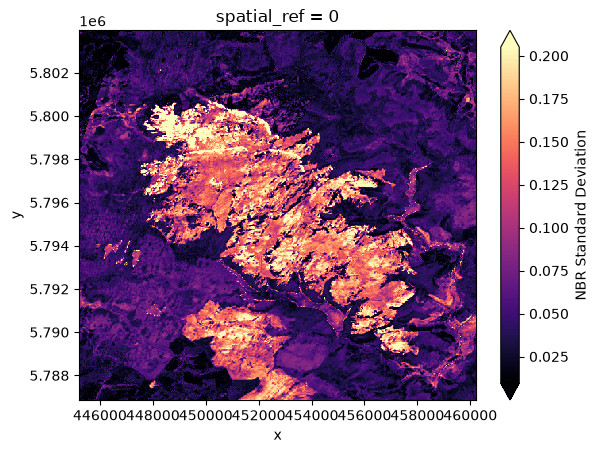

In [64]:
nbr_std.plot.imshow(cmap="magma", robust=True, cbar_kwargs={"label": "NBR Standard Deviation"})
plt.show()

More methods of aggregating are shown [in the `xarray` documation here](https://docs.xarray.dev/en/latest/api/dataarray.html#aggregation).

Ultimately, our data and use case probably isn't perfectly appropriate for calculating full-stack statistics: it is more appropriate to compare values across time-steps than calculate long-term statistics. 

A more appropriate use case might be, for example, calculate median values over entire seasons/years, and comparing those. However, this will require large quantities of images that might not be convenient to download and/or manage. Next week, we will begin to explore how we can using geospatial cloud computing services to make this large-scale assessment easier for us...

## Summary

We have learned how we can stitch together individual files into a large datacube with a manually inserted datetime axis. Once this datacube was created, we considered a number of different ways we could use `xarray` features to interrogate the dataset, including raster differencing, tracking changes in area and zonal statistics through time, and calculating statistics over the entire time stack.